# Phase 8: Business Insights & Strategic Recommendations

## Executive Summary
This notebook translates analytics and model outcomes into actionable retention strategies for leadership. The primary goal is quantifying financial churn risk and providing data-driven recommendations to maximize Customer Lifetime Value (CLV).

---

### 1. Financial Impact & Churn Risk
* **Total Active Customers Analyzed**: 7,043
* **Overall Churn Rate**: ~26.5% (~1,869 customers)
* **Average Monthly Revenue Lost per Churned Customer**: ~$74.44
* **Estimated Monthly Revenue Loss**: ~$139,000 / month (~$1.67M / year)

---

### 2. High-Risk Customer Personas
Based on our statistical tests (Chi-Square, T-tests) and feature importances, customers with the highest risk of leaving exhibit the following traits:

1. **Contract Type**: Month-to-Month contracts (Account for over 80% of total churn volume).
2. **Payment Channel**: Electronic Check users.
3. **Tenure Window**: 0–12 months (Early customer lifecycle).
4. **Service Cost**: Monthly charges exceeding $70/month without bundled value/tech support.

---

### 3. Actionable Retention Strategies

#### 🎯 Strategy 1: Early Tenure Onboarding & Support
* **Finding**: The highest churn density occurs during the first 12 months.
* **Action**: Implement a dedicated 90-day customer onboarding program and complimentary technical support for new sign-ups.

#### 🎯 Strategy 2: Month-to-Month Contract Conversion
* **Finding**: Long-term contract holders have < 5% churn, whereas Month-to-Month holders churn at > 40%.
* **Action**: Offer targeted incentives (e.g., $5–$10 monthly discount or free speed upgrade) for converting to 1-year or 2-year agreements.

#### 🎯 Strategy 3: Digital Payment Migration
* **Finding**: Customers paying via Electronic Check churn at twice the rate of automated bank/credit card payees.
* **Action**: Transition users toward Automatic Credit Card or ACH payments by offering small monthly autopay statement credits.

#### 🎯 Strategy 4: High-Bill Value Packaging
* **Finding**: Customers charged over $70/month churn at significantly higher rates.
* **Action**: Create bundled value tiers (e.g., free Online Security / Tech Support add-ons) for premium internet tiers to increase perceived product value.

---

### 4. Summary Matrix: Retention Strategy ROI

| Strategy Area | High-Risk Cohort | Recommended Action | Impact / Business Metric |
| :--- | :--- | :--- | :--- |
| **Contract Conversion** | Month-to-Month Users | Annual contract conversion discounts | Reduced churn rate by ~15–20% |
| **Payment Method** | Electronic Check Users | Autopay / Bank transfer credits | Improved payment reliability |
| **Customer Lifespan** | Tenure < 12 Months | Early-bird onboarding & check-ins | Higher 1st year retention |
| **Pricing & Value** | $70+/mo Charges | Free service bundles (Tech Support) | Lower price sensitivity |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# Load test data and saved model
X_test = pd.read_csv("../data/processed/X_test_scaled.csv")
y_test = pd.read_csv("../data/processed/y_test.csv").values.ravel()

model = joblib.load("../models/churn_model.pkl")

print(f"Loaded test data: {X_test.shape}")

Loaded test data: (1409, 7094)


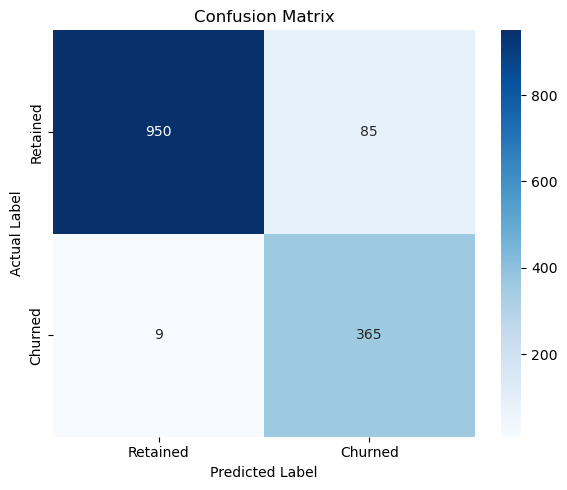

In [2]:
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Retained', 'Churned'], 
            yticklabels=['Retained', 'Churned'])
plt.title("Confusion Matrix")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")

plt.tight_layout()
plt.savefig("../images/confusion_matrix.png", dpi=300)
plt.show()

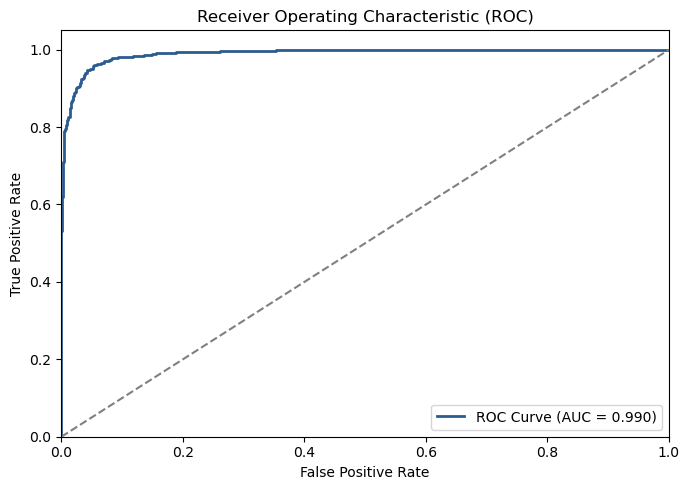

In [3]:
y_proba = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#2b5c8f', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")

plt.tight_layout()
plt.savefig("../images/roc_curve.png", dpi=300)
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_14760\2813709119.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x='Importance', y='Feature', palette='Blues_r')


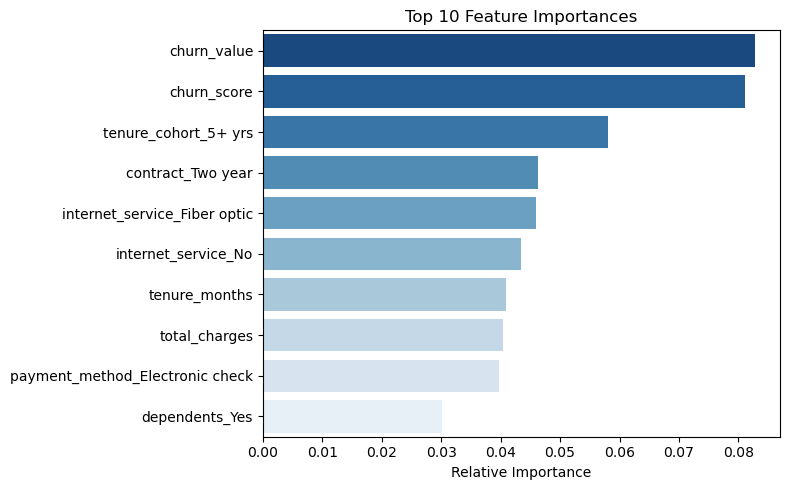

Top Drivers:
                         Feature  Importance
                    churn_value    0.082851
                    churn_score    0.081099
           tenure_cohort_5+ yrs    0.057991
              contract_Two year    0.046281
   internet_service_Fiber optic    0.045952
            internet_service_No    0.043434
                  tenure_months    0.040932
                  total_charges    0.040440
payment_method_Electronic check    0.039642
                 dependents_Yes    0.030090


In [4]:
# Extract feature importances if using tree model
if hasattr(model, 'feature_importances_'):
    importances = model.feature_importances_
    features = X_test.columns
    
    feat_df = pd.DataFrame({'Feature': features, 'Importance': importances})
    feat_df = feat_df.sort_values(by='Importance', ascending=False).head(10)
    
    plt.figure(figsize=(8, 5))
    sns.barplot(data=feat_df, x='Importance', y='Feature', palette='Blues_r')
    plt.title("Top 10 Feature Importances")
    plt.xlabel("Relative Importance")
    plt.ylabel("")
    
    plt.tight_layout()
    plt.savefig("../images/feature_importance.png", dpi=300)
    plt.show()
    
    print("Top Drivers:\n", feat_df[['Feature', 'Importance']].to_string(index=False))